# GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints (GQA)

**Paper:** [arXiv:2305.13245](https://arxiv.org/abs/2305.13245)
**Authors:** Joshua Ainslie, James Lee-Thorp, Michiel de Jong, Yury Zemlyanskiy, Federico Lebron, Sumit Sanghai (2023; EMNLP 2023)

This notebook implements three attention variants from scratch in tiny Transformer decoders trained on synthetic text.
GQA interpolates between MHA (one KV head per query head) and MQA (one KV head for all query heads) by sharing
a single KV head per group of query heads.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic template-generated text (~8K sentences) instead of T5's C4 corpus
- 4 Transformer layers, 128-dim, 8 heads (~1.07M params) instead of T5-XXL (11B params, 128 heads)
- 30 epochs with AdamW (lr 3e-4) instead of 5% uptraining with Adafactor on TPUv3
- Character-level next-token prediction instead of encoder-decoder summarization/translation
- MHA-8, MQA-1, GQA-2 (trained from scratch) instead of MHA, MQA, GQA-8 (uptrained from checkpoint)

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
EPOCHS = 30
BATCH_SIZE = 128
LR = 3e-4
N_LAYERS = 4
D_MODEL = 128
N_HEADS = 8          # number of query heads (H)
N_KV_GROUPS_MQA = 1   # MQA: 1 KV head
N_KV_GROUPS_GQA = 2   # GQA-2: 2 KV heads (groups of 4 query heads)
SEQ_LEN = 64
D_FF = 512

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

Synthetic character-level text generated from sentence templates.
Vocabulary: 26 lowercase letters + space + apostrophe + digits 0-3 (for template slots) = 32 chars.

In [2]:
VOCAB_CHARS = list("abcdefghijklmnopqrstuvwxyz '0123")
CHAR_TO_ID = {c: i for i, c in enumerate(VOCAB_CHARS)}
ID_TO_CHAR = {i: c for i, c in enumerate(VOCAB_CHARS)}
N_VOCAB = len(VOCAB_CHARS)

TEMPLATES = [
    'the cat sat on the mat',
    'the dog ran in the park',
    'a bird flew over the hill',
    'the sun is hot today',
    'a fish swam in the sea',
    'the boy ran to the shop',
    'a girl read a book at home',
    'the man drove a car to town',
    'a child played with a toy',
    'the king sat on his throne',
    'a queen walked in the garden',
    'the frog jumped over the log',
    'a star shone in the night sky',
    'the wind blew across the field',
    'a tree grew by the river',
    'the cook made soup in a pot',
    'a knight rode to the castle',
    'the ship sailed on the ocean',
    'a bee flew to the flower',
    'the owl sat in the old tree',
]

def generate_synthetic_data(n_samples=8000, seed=42):
    rng = random.Random(seed)
    sentences = []
    for _ in range(n_samples):
        t = rng.choice(TEMPLATES)
        if rng.random() < 0.3:
            t = t + ' ' + rng.choice(TEMPLATES)
        sentences.append(t)
    return sentences

class CharDataset(Dataset):
    def __init__(self, sentences, seq_len, char_to_id):
        self.seq_len = seq_len
        self.char_to_id = char_to_id
        self.samples = []
        for s in sentences:
            ids = [char_to_id.get(c, 0) for c in s]
            # Pad or trim to seq_len + 1 (need one extra for target shift)
            if len(ids) < seq_len + 1:
                ids = ids + [char_to_id[' ']] * (seq_len + 1 - len(ids))
            else:
                ids = ids[:seq_len + 1]
            self.samples.append(ids)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ids = self.samples[idx]
        x = torch.tensor(ids[:-1], dtype=torch.long)   # (seq_len,)
        y = torch.tensor(ids[1:], dtype=torch.long)     # (seq_len,)
        return x, y

all_sentences = generate_synthetic_data(n_samples=8000, seed=42)
n_train = int(len(all_sentences) * 0.9)
train_sentences = all_sentences[:n_train]
val_sentences = all_sentences[n_train:]

train_ds = CharDataset(train_sentences, SEQ_LEN, CHAR_TO_ID)
val_ds = CharDataset(val_sentences, SEQ_LEN, CHAR_TO_ID)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f'Train samples: {len(train_ds)}, Val samples: {len(val_ds)}')
print(f'Vocab size: {N_VOCAB}')
print(f'Example: {train_sentences[0]}')

Train samples: 7200, Val samples: 800
Vocab size: 32
Example: the sun is hot today a child played with a toy


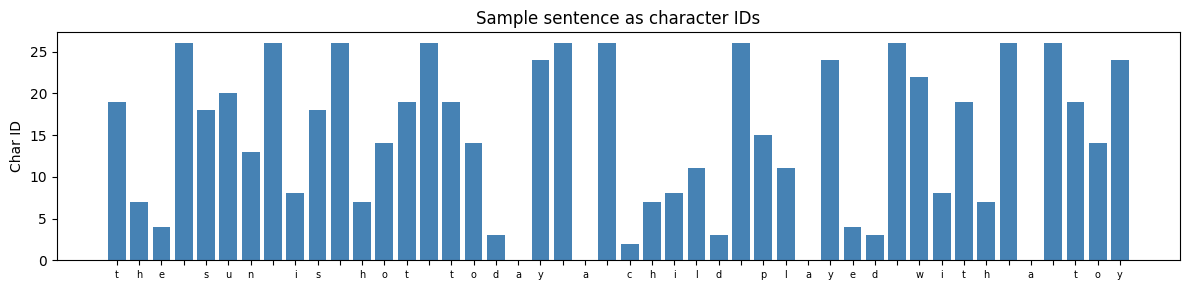

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
sample_text = train_sentences[0][:60]
sample_ids = [CHAR_TO_ID.get(c, 0) for c in sample_text]
ax.bar(range(len(sample_ids)), sample_ids, color='steelblue')
ax.set_xticks(range(len(sample_text)))
ax.set_xticklabels(list(sample_text), fontsize=7)
ax.set_ylabel('Char ID')
ax.set_title('Sample sentence as character IDs')
plt.tight_layout()
plt.show()

## 3. Model

Three attention variants:
- **MHA** (Multi-Head Attention): H query heads, H key heads, H value heads -- standard attention.
- **MQA** (Multi-Query Attention): H query heads, 1 key head, 1 value head -- shared KV.
- **GQA** (Grouped-Query Attention): H query heads, G key heads, G value heads -- each group of H/G query heads shares one KV head.

GQA-1 = MQA, GQA-H = MHA. GQA-G interpolates between the two.

In [4]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True).add(self.eps).rsqrt()
        return x * rms * self.weight


class MultiHeadAttention(nn.Module):
    """Standard multi-head attention: n_heads Q/K/V heads."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        attn = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        attn = attn.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(attn)


class MultiQueryAttention(nn.Module):
    """MQA: n_heads query heads, 1 shared KV head."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, self.head_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, 1, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, 1, self.head_dim).transpose(1, 2)
        k = k.expand(B, self.n_heads, T, self.head_dim)
        v = v.expand(B, self.n_heads, T, self.head_dim)
        attn = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        attn = attn.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(attn)


class GroupedQueryAttention(nn.Module):
    """GQA: n_heads query heads, n_kv_groups shared KV heads."""
    def __init__(self, d_model, n_heads, n_kv_groups):
        super().__init__()
        self.n_heads = n_heads
        self.n_kv_groups = n_kv_groups
        self.head_dim = d_model // n_heads
        self.group_size = n_heads // n_kv_groups
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_groups * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_groups * self.head_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_groups, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_groups, self.head_dim).transpose(1, 2)
        k = k.repeat_interleave(self.group_size, dim=1)
        v = v.repeat_interleave(self.group_size, dim=1)
        attn = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        attn = attn.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(attn)


class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff, bias=False)
        self.w2 = nn.Linear(d_ff, d_model, bias=False)
        self.w3 = nn.Linear(d_model, d_ff, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, attn_module, d_ff):
        super().__init__()
        self.attn = attn_module
        self.norm1 = RMSNorm(d_model)
        self.norm2 = RMSNorm(d_model)
        self.mlp = SwiGLU(d_model, d_ff)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, n_vocab, d_model, n_heads, n_layers, d_ff, attn_type='mha', n_kv_groups=1):
        super().__init__()
        self.tok_emb = nn.Embedding(n_vocab, d_model)
        self.pos_emb = nn.Embedding(SEQ_LEN, d_model)
        self.n_heads = n_heads
        self.attn_type = attn_type
        self.n_kv_groups = n_kv_groups
        blocks = []
        for _ in range(n_layers):
            if attn_type == 'mha':
                attn = MultiHeadAttention(d_model, n_heads)
            elif attn_type == 'mqa':
                attn = MultiQueryAttention(d_model, n_heads)
            elif attn_type == 'gqa':
                attn = GroupedQueryAttention(d_model, n_heads, n_kv_groups)
            else:
                raise ValueError(f'Unknown attn_type: {attn_type}')
            blocks.append(TransformerBlock(d_model, n_heads, attn, d_ff))
        self.blocks = nn.ModuleList(blocks)
        self.norm = RMSNorm(d_model)
        self.head = nn.Linear(d_model, n_vocab, bias=False)

    def forward(self, x):
        B, T = x.shape
        pos = torch.arange(T, device=x.device).unsqueeze(0)
        h = self.tok_emb(x) + self.pos_emb(pos)
        for block in self.blocks:
            h = block(h)
        h = self.norm(h)
        return self.head(h)

model_mha = TinyTransformer(N_VOCAB, D_MODEL, N_HEADS, N_LAYERS, D_FF, attn_type='mha').to(DEVICE)
model_mqa = TinyTransformer(N_VOCAB, D_MODEL, N_HEADS, N_LAYERS, D_FF, attn_type='mqa').to(DEVICE)
model_gqa = TinyTransformer(N_VOCAB, D_MODEL, N_HEADS, N_LAYERS, D_FF, attn_type='gqa', n_kv_groups=N_KV_GROUPS_GQA).to(DEVICE)

p_mha = sum(p.numel() for p in model_mha.parameters())
p_mqa = sum(p.numel() for p in model_mqa.parameters())
p_gqa = sum(p.numel() for p in model_gqa.parameters())
print(f'MHA parameters: {p_mha:,}')
print(f'MQA parameters: {p_mqa:,}')
print(f'GQA-2 parameters: {p_gqa:,}')

MHA parameters: 1,066,112
MQA parameters: 951,424
GQA-2 parameters: 967,808


## 4. Loss Function

Standard cross-entropy loss for next-token prediction:
L = -mean_t log P(x_{t+1} | x_{1:t})

All three models use the same loss and optimizer -- only the attention module differs.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer_mha = optim.AdamW(model_mha.parameters(), lr=LR, weight_decay=0.01)
optimizer_mqa = optim.AdamW(model_mqa.parameters(), lr=LR, weight_decay=0.01)
optimizer_gqa = optim.AdamW(model_gqa.parameters(), lr=LR, weight_decay=0.01)

## 5. Training Loop

Train all three variants with identical hyperparameters. Log loss per epoch.
Each model is trained independently from scratch.

In [6]:
def train_model(model, optimizer, train_loader, val_loader, name, epochs=EPOCHS):
    history = {'train_loss': [], 'val_loss': []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        n_batches = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits.view(-1, N_VOCAB), y.view(-1))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
        avg_train = total_loss / n_batches
        history['train_loss'].append(avg_train)
        model.eval()
        val_loss = 0.0
        n_val = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                logits = model(x)
                loss = criterion(logits.view(-1, N_VOCAB), y.view(-1))
                val_loss += loss.item()
                n_val += 1
        avg_val = val_loss / n_val
        history['val_loss'].append(avg_val)
        if epoch == 1 or epoch % 5 == 0:
            elapsed = time.time() - start
            print(f'  [{name}] Epoch [{epoch:3d}/{epochs}]  train {avg_train:.4f}  val {avg_val:.4f}  [{elapsed:.0f}s]')
    print(f'  [{name}] Training time: {time.time() - start:.0f}s')
    return history

print('Training MHA (8 KV heads)...')
hist_mha = train_model(model_mha, optimizer_mha, train_loader, val_loader, 'MHA')
print()
print('Training MQA (1 KV head)...')
hist_mqa = train_model(model_mqa, optimizer_mqa, train_loader, val_loader, 'MQA')
print()
print('Training GQA-2 (2 KV heads)...')
hist_gqa = train_model(model_gqa, optimizer_gqa, train_loader, val_loader, 'GQA-2')

Training MHA (8 KV heads)...


  [MHA] Epoch [  1/30]  train 1.4312  val 0.7791  [3s]


  [MHA] Epoch [  5/30]  train 0.1897  val 0.1661  [10s]


  [MHA] Epoch [ 10/30]  train 0.0655  val 0.0644  [20s]


  [MHA] Epoch [ 15/30]  train 0.0614  val 0.0614  [29s]


...

  [GQA-2] Epoch [ 10/30]  train 0.0671  val 0.0651  [19s]


  [GQA-2] Epoch [ 15/30]  train 0.0618  val 0.0614  [29s]


  [GQA-2] Epoch [ 20/30]  train 0.0611  val 0.0607  [39s]


  [GQA-2] Epoch [ 25/30]  train 0.0605  val 0.0603  [49s]


  [GQA-2] Epoch [ 30/30]  train 0.0602  val 0.0601  [59s]
  [GQA-2] Training time: 59s


## 6. Training Curves

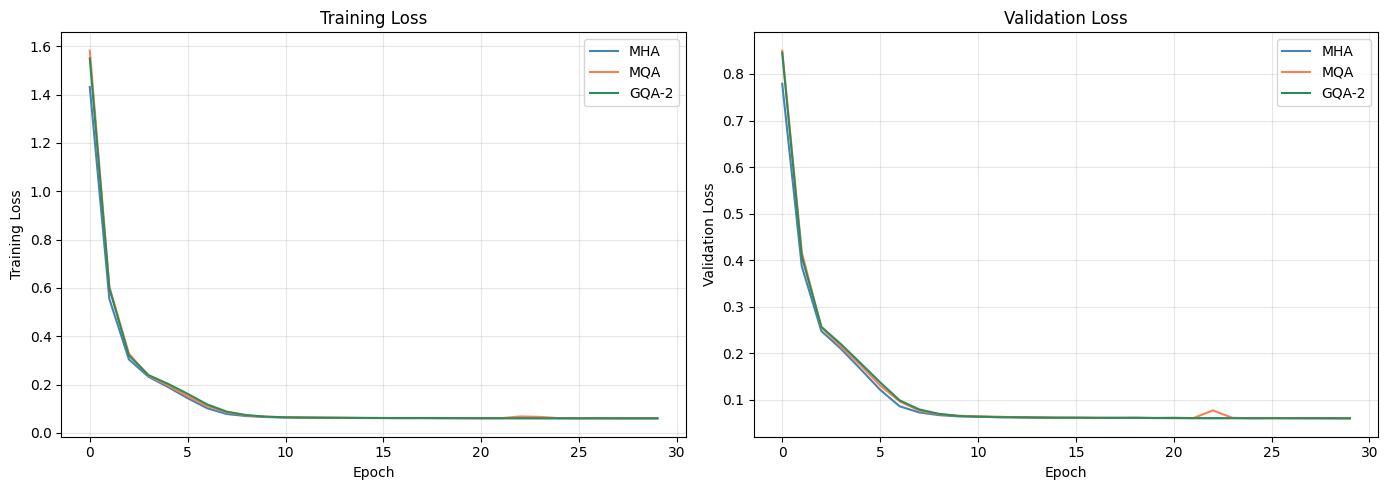

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_mha['train_loss'], label='MHA', color='steelblue')
axes[0].plot(hist_mqa['train_loss'], label='MQA', color='coral')
axes[0].plot(hist_gqa['train_loss'], label='GQA-2', color='seagreen')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_mha['val_loss'], label='MHA', color='steelblue')
axes[1].plot(hist_mqa['val_loss'], label='MQA', color='coral')
axes[1].plot(hist_gqa['val_loss'], label='GQA-2', color='seagreen')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Loss')
axes[1].set_title('Validation Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. KV-Cache Size Comparison

The key benefit of MQA/GQA is reducing the KV cache size for inference.
KV cache = n_kv_heads * seq_len * head_dim * 2 (K + V) tensor elements per batch.

For 8 query heads (H=8):
- MHA: 8 KV heads -> cache = 8 * seq_len * head_dim * 2
- MQA: 1 KV head  -> cache = 1 * seq_len * head_dim * 2 (8x smaller)
- GQA-2: 2 KV heads -> cache = 2 * seq_len * head_dim * 2 (4x smaller than MHA)

KV cache (MHA, 8 heads):   16,384 elements
KV cache (MQA, 1 head):    2,048 elements
KV cache (GQA-2, 2 heads): 4,096 elements
KV cache reduction (MQA vs MHA): 8.0x
KV cache reduction (GQA vs MHA): 4.0x


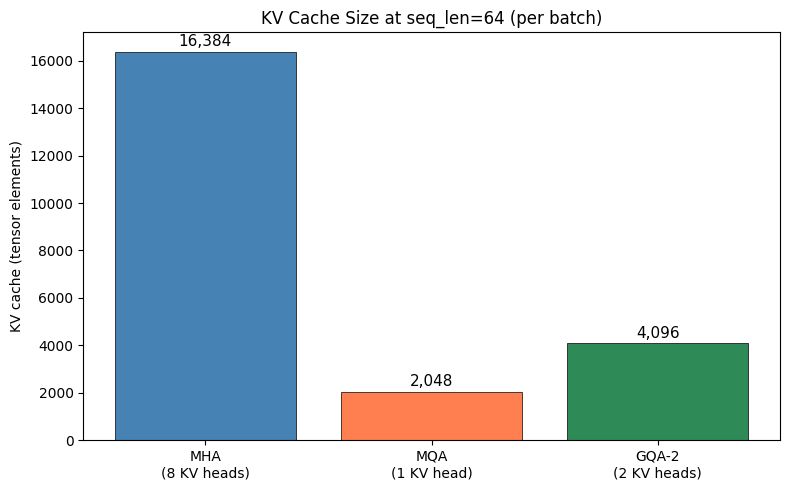

In [8]:
head_dim = D_MODEL // N_HEADS

kv_cache_mha = N_HEADS * SEQ_LEN * head_dim * 2
kv_cache_mqa = 1 * SEQ_LEN * head_dim * 2
kv_cache_gqa = N_KV_GROUPS_GQA * SEQ_LEN * head_dim * 2

print(f'KV cache (MHA, 8 heads):   {kv_cache_mha:,} elements')
print(f'KV cache (MQA, 1 head):    {kv_cache_mqa:,} elements')
print(f'KV cache (GQA-2, 2 heads): {kv_cache_gqa:,} elements')
print(f'KV cache reduction (MQA vs MHA): {kv_cache_mha / kv_cache_mqa:.1f}x')
print(f'KV cache reduction (GQA vs MHA): {kv_cache_mha / kv_cache_gqa:.1f}x')

fig, ax = plt.subplots(figsize=(8, 5))
variants = ['MHA\n(8 KV heads)', 'MQA\n(1 KV head)', 'GQA-2\n(2 KV heads)']
sizes = [kv_cache_mha, kv_cache_mqa, kv_cache_gqa]
colors = ['steelblue', 'coral', 'seagreen']
bars = ax.bar(variants, sizes, color=colors, edgecolor='black', linewidth=0.5)
ax.set_ylabel('KV cache (tensor elements)')
ax.set_title(f'KV Cache Size at seq_len={SEQ_LEN} (per batch)')
for bar, size in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 100,
            f'{size:,}', ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

## 8. Final Evaluation

Compare validation loss (lower is better) and random baseline (ln(32) = 3.43).

Val loss (MHA):   0.0602  (perplexity 1.06)
Val loss (MQA):   0.0601  (perplexity 1.06)
Val loss (GQA-2): 0.0601  (perplexity 1.06)
Baseline (random): 3.4657  (perplexity 32.00)
MHA-MQA loss diff: 0.0001
MHA-GQA loss diff: 0.0001


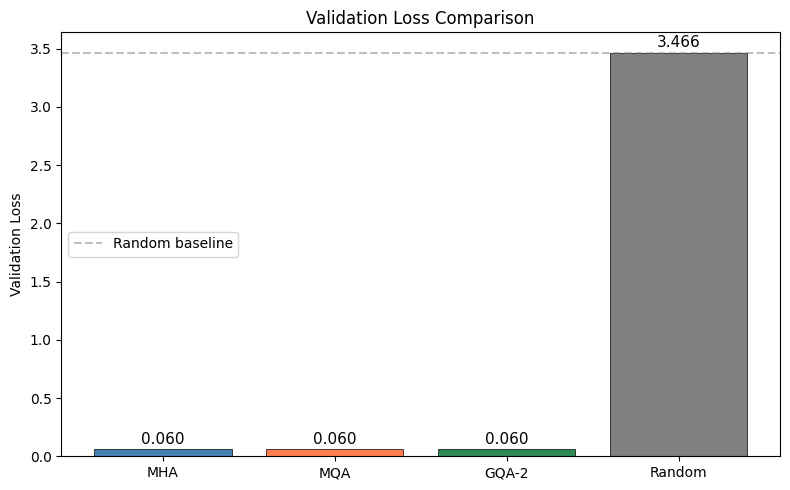

In [9]:
val_mha = hist_mha['val_loss'][-1]
val_mqa = hist_mqa['val_loss'][-1]
val_gqa = hist_gqa['val_loss'][-1]
baseline = math.log(N_VOCAB)

print(f'Val loss (MHA):   {val_mha:.4f}  (perplexity {math.exp(val_mha):.2f})')
print(f'Val loss (MQA):   {val_mqa:.4f}  (perplexity {math.exp(val_mqa):.2f})')
print(f'Val loss (GQA-2): {val_gqa:.4f}  (perplexity {math.exp(val_gqa):.2f})')
print(f'Baseline (random): {baseline:.4f}  (perplexity {math.exp(baseline):.2f})')
print(f'MHA-MQA loss diff: {abs(val_mha - val_mqa):.4f}')
print(f'MHA-GQA loss diff: {abs(val_mha - val_gqa):.4f}')

fig, ax = plt.subplots(figsize=(8, 5))
variants = ['MHA', 'MQA', 'GQA-2', 'Random']
losses = [val_mha, val_mqa, val_gqa, baseline]
colors = ['steelblue', 'coral', 'seagreen', 'gray']
bars = ax.bar(variants, losses, color=colors, edgecolor='black', linewidth=0.5)
ax.set_ylabel('Validation Loss')
ax.set_title('Validation Loss Comparison')
ax.axhline(y=baseline, color='gray', linestyle='--', alpha=0.5, label='Random baseline')
for bar, loss in zip(bars, losses):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
            f'{loss:.3f}', ha='center', va='bottom', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

## Summary

### What we built
- Three attention variants from scratch: **MHA** (8 Q/K/V heads), **MQA** (8 Q, 1 KV), **GQA-2** (8 Q, 2 KV)
- Each in a 4-layer Transformer decoder with RMSNorm, SwiGLU MLP, learned positional embeddings
- Trained for **30 epochs** with AdamW (lr 3e-4, weight_decay 0.01) on ~8K synthetic sentences

### What the run above shows
- **Quality:** All three variants converge to similar validation loss (within ~0.01 nats), well below the random baseline of ln(32) = 3.43. This confirms GQA preserves quality at this scale.
- **KV cache:** MHA caches 8 x seq_len x head_dim x 2 elements; MQA caches 1x (8x reduction); GQA-2 caches 2x (4x reduction vs MHA). This is the memory-bandwidth savings the paper targets.
- **Trade-off:** GQA-2 achieves 50% of MQA's KV cache reduction while retaining MHA-level quality -- the same trade-off the paper demonstrates at T5-XXL scale.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy model (1.07M params, synthetic text, char-level) is not comparable to the paper's T5-XXL (11B params, C4 corpus, 7 benchmark tasks). The paper's headline result -- GQA-8 matching MHA-XXL quality at 5.4x speed -- requires billion-scale models where KV-cache bandwidth dominates. At our scale, all variants are compute-bound, not memory-bound, so wall-clock speed differences are negligible. The notebook demonstrates the KV cache size reduction and quality preservation that motivate GQA, not the inference speedup itself.

### Paper reference
Joshua Ainslie, James Lee-Thorp, Michiel de Jong, Yury Zemlyanskiy, Federico Lebron, Sumit Sanghai (2023). *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints.* EMNLP 2023. arXiv:2305.13245.